In [32]:
from food_truck_optimizer import load_trucks, solve, report
from gurobipy import GRB
import csv
import matplotlib.pyplot as plt
trucks = load_trucks("../data/food_trucks.csv")
q_min = float(input("Minimum average qualtiy rating: "))
budget = float(input("Total event budget: "))
max_space = float(input("Maximum total space available:  "))
m,y, _ = solve(trucks, q_min, budget, max_space)
report(m, y, trucks, q_min, budget, max_space)

Minimum average qualtiy rating:  4.2
Total event budget:  14000
Maximum total space available:   1700


Gurobi Optimizer version 12.0.3 build v12.0.3rc0 (win64 - Windows 11+.0 (26200.2))

CPU model: Intel(R) Core(TM) Ultra 7 155U, instruction set [SSE2|AVX|AVX2]
Thread count: 12 physical cores, 14 logical processors, using up to 14 threads

Optimize a model with 17 rows, 17 columns and 118 nonzeros
Model fingerprint: 0x499fdc4b
Variable types: 0 continuous, 17 integer (17 binary)
Coefficient statistics:
  Matrix range     [1e-01, 2e+03]
  Objective range  [2e+03, 4e+03]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 1e+04]
Found heuristic solution: objective 23800.000000
Presolve removed 3 rows and 0 columns
Presolve time: 0.00s
Presolved: 14 rows, 17 columns, 82 nonzeros
Variable types: 0 continuous, 17 integer (17 binary)

Root relaxation: objective 2.860738e+04, 13 iterations, 0.00 seconds (0.00 work units)

    Nodes    |    Current Node    |     Objective Bounds      |     Work
 Expl Unexpl |  Obj  Depth IntInf | Incumbent    BestBd   Gap | It/Node Time

     0     0 2

In [22]:
chosen = [t for i, t in enumerate(trucks) if y[i].X > 0.5]
with open("../results/optimal_schedule.csv", "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["Truck", "Category", "Revenue($)", "Cost($)", "Net Profit($)", "Space(sq ft)", "Quality"])
    for t in chosen:
        writer.writerow([t["name"], t["category"], t["revenue"], t["cost"], t["revenue"]- t["cost"], t["space"], t["quality"]])

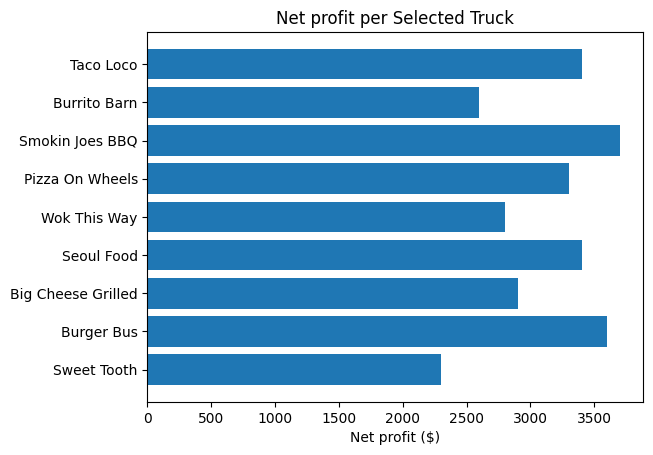

In [34]:
names = [t["name"] for t in chosen]
profits = [t["revenue"] - t["cost"] for t in chosen]
plt.barh(names[::-1], profits[::-1])
plt.title  ("Net profit per Selected Truck")
plt.xlabel("Net profit ($)")
plt.savefig("../results/selected_truck_profit.png", bbox_inches = "tight")
plt.show()

In [30]:
budgets = [int(budget * mult) for mult in [0.5, 0.65, 0.8, 0.9, 1.0, 1.1, 1.25, 1.4 , 1.5]]
sensitive_profits = []
for b in budgets:
    m_temp, _, _ = solve(trucks, q_min,b, max_space)
    sensitive_profits.append(m_temp.ObjVal if m_temp.Status == GRB.OPTIMAL else None)
    

Gurobi Optimizer version 12.0.3 build v12.0.3rc0 (win64 - Windows 11+.0 (26200.2))

CPU model: Intel(R) Core(TM) Ultra 7 155U, instruction set [SSE2|AVX|AVX2]
Thread count: 12 physical cores, 14 logical processors, using up to 14 threads

Optimize a model with 17 rows, 17 columns and 118 nonzeros
Model fingerprint: 0xb5e5ddbf
Variable types: 0 continuous, 17 integer (17 binary)
Coefficient statistics:
  Matrix range     [1e-01, 2e+03]
  Objective range  [2e+03, 4e+03]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 7e+03]
Presolve removed 4 rows and 0 columns
Presolve time: 0.00s
Presolved: 13 rows, 17 columns, 65 nonzeros
Variable types: 0 continuous, 17 integer (17 binary)

Root relaxation: infeasible, 7 iterations, 0.00 seconds (0.00 work units)

    Nodes    |    Current Node    |     Objective Bounds      |     Work
 Expl Unexpl |  Obj  Depth IntInf | Incumbent    BestBd   Gap | It/Node Time

     0     0 infeasible    0               - infeasible      -     -    0s



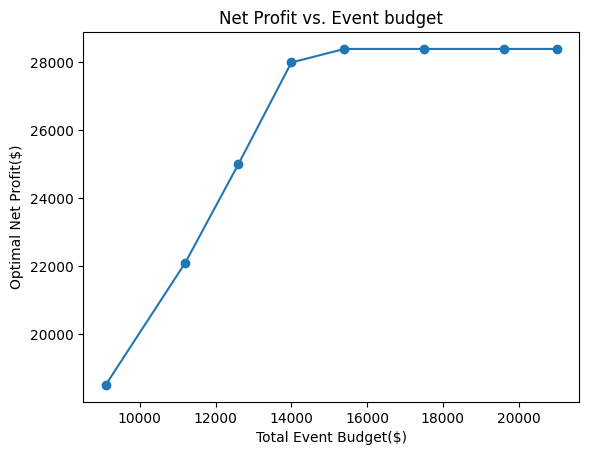

In [36]:
plt.plot(budgets, sensitive_profits, marker="o")
plt.title("Net Profit vs. Event budget")
plt.xlabel("Total Event Budget($)")
plt.ylabel("Optimal Net Profit($)")
plt.savefig("../results/budget_sensitivity.png", bbox_inches = "tight")
plt.show()